# FoAViS demo: where does the model look?

<a target="_blank" href="https://colab.research.google.com/github/ecker-lab/FoAViS/blob/main/demo.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook runs the pre-trained FoAViS models on single images. For each image it shows where the model fixates,
the policy map from which each next fixation is drawn, and the model's prediction: an ImageNet class or an ADE20K
segmentation. The models are downloaded on first use (about 60 MB each). A GPU is not required; on a CPU each image
takes a few seconds.

## Setup

On Google Colab, the first cell clones the repository and installs the one missing package. Locally, run the notebook from the repository root in the `foavis` environment (see the README).

In [1]:
import os, sys
if "google.colab" in sys.modules and not os.path.exists("foavis"):
    !git clone -q https://github.com/ecker-lab/FoAViS
    %cd FoAViS
    !pip install -q dotmap

In [2]:
from foavis.predict import load_model, predict, show

## Classification (ImageNet)

`load_model` takes the name of a released model, `<dataset>_<policy>_s1` (see `docs/evaluation.md`). The learned-policy
model looks at the image in four glimpses: the first at the centre, each following one drawn from its policy.

In [3]:
model = load_model("imagenet_learned_s1")
result = predict(model, "docs/examples/cat.jpg")
result.top(5)

Loaded checkpoints/imagenet_learned_s1.pth (epoch 73, metric 68.3724)


[('tabby', 0.7362502217292786),
 ('tiger cat', 0.1311611384153366),
 ('Egyptian cat', 0.1272975206375122),
 ('lynx', 0.0031749154441058636),
 ('window screen', 0.0011849318398162723)]

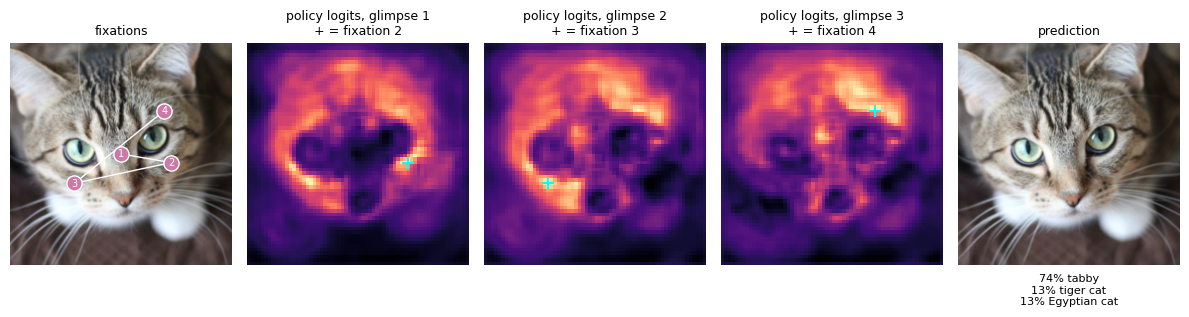

In [4]:
show(result);

Left: the four fixations in order. Middle: the policy-head logits after glimpses 1 to 3; the softmax over all cells is
the probability map, and its most likely cell (cyan `+`) is the next fixation. Right: the final prediction.

The fixations are also returned as an array, in normalized image coordinates `(x, y)` with `(-1, -1)` the top left
and `(1, 1)` the bottom right corner:

In [5]:
result.fixations

array([[ 0.      ,  0.      ],
       [ 0.453125,  0.078125],
       [-0.421875,  0.265625],
       [ 0.390625, -0.390625]], dtype=float32)

## Semantic segmentation (ADE20K)

The same model architecture, trained on ADE20K, reads its memory out densely and labels every pixel with one of 150
classes.

In [6]:
seg_model = load_model("ade20k_learned_s1")
result = predict(seg_model, "docs/examples/living_room.jpg")
result.classes_present()[:8]

Loaded checkpoints/ade20k_learned_s1.pth (epoch 499, metric 24.193065)


[('wall', 0.194549560546875),
 ('floor', 0.17832183837890625),
 ('curtain', 0.14461517333984375),
 ('ceiling', 0.11751174926757812),
 ('cabinet', 0.1103668212890625),
 ('mirror', 0.044506072998046875),
 ('door', 0.04236602783203125),
 ('sofa', 0.03563690185546875)]

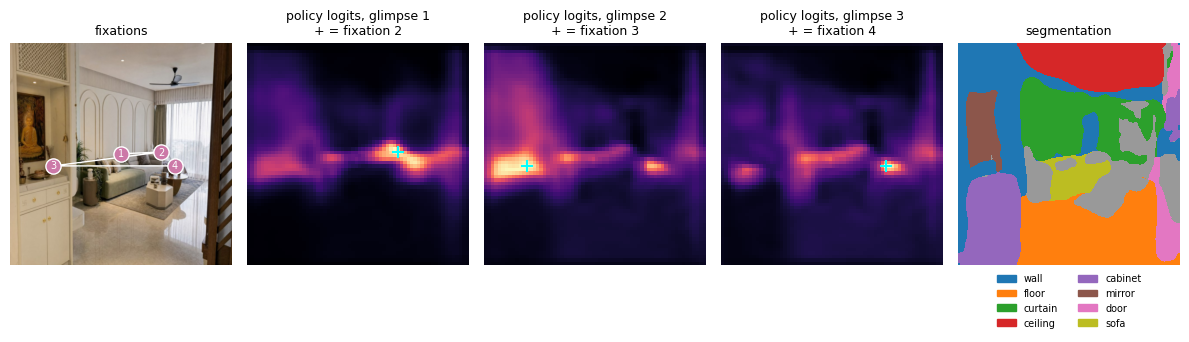

In [7]:
show(result);

## Changing the policy or the number of glimpses

`load_model` accepts `policy` (`learned`, `random`, `triangle`, `quadrant`, `saliency` for classification, `entropy`
for segmentation) and `num_glimpses`. Here the learned-policy ImageNet model looks at random locations instead of
choosing them itself, and then takes eight glimpses with its own policy.

Loaded checkpoints/imagenet_learned_s1.pth (epoch 73, metric 68.3724)


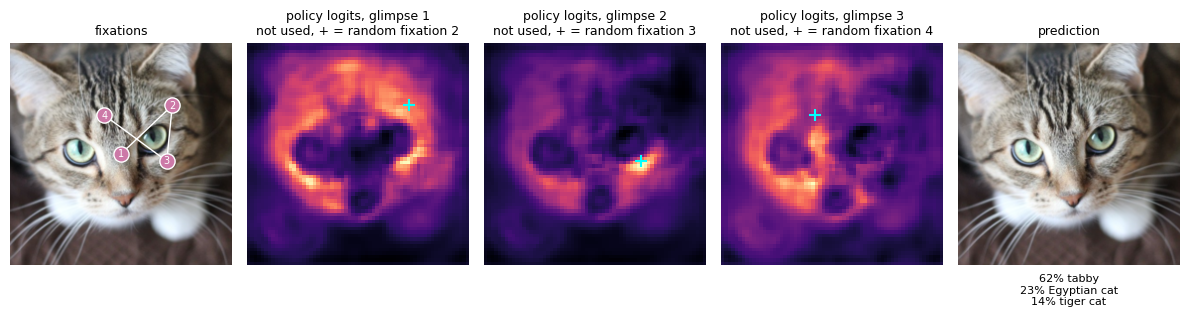

In [8]:
random_locations = load_model("imagenet_learned_s1", policy="random")
show(predict(random_locations, "docs/examples/cat.jpg"));

Loaded checkpoints/imagenet_learned_s1.pth (epoch 73, metric 68.3724)


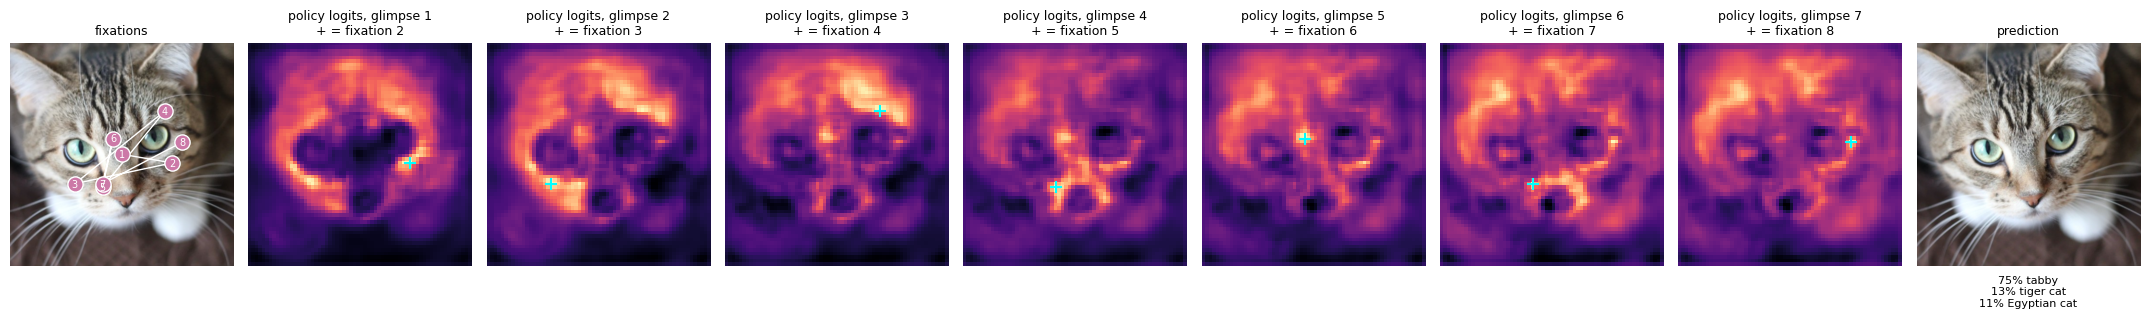

In [9]:
eight_glimpses = load_model("imagenet_learned_s1", num_glimpses=8)
show(predict(eight_glimpses, "docs/examples/cat.jpg"));

## Your own image

Replace the path with your own image (on Colab, upload it with the folder icon on the left). ImageNet models expect a
photo of a single object, the segmentation models (`ade20k_learned_s1`, `coco_stuff_learned_s1`) a scene.

In [ ]:
show(predict(model, "docs/examples/cat.jpg"));

The same is available on the command line:

```bash
python -m foavis.predict my_photo.jpg --model imagenet_learned_s1
```